# HR EMPLOYEE ATTRITION ANALYSIS USING PYTHON

## Objective

To analyze employee attrition using Python and identify the factors and patterns associated with employee turnover.

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
df=pd.read_csv("data.csv")

In [5]:
df.head()

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


In [6]:
df.shape

(1470, 35)

In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   Age                       1470 non-null   int64
 1   Attrition                 1470 non-null   str  
 2   BusinessTravel            1470 non-null   str  
 3   DailyRate                 1470 non-null   int64
 4   Department                1470 non-null   str  
 5   DistanceFromHome          1470 non-null   int64
 6   Education                 1470 non-null   int64
 7   EducationField            1470 non-null   str  
 8   EmployeeCount             1470 non-null   int64
 9   EmployeeNumber            1470 non-null   int64
 10  EnvironmentSatisfaction   1470 non-null   int64
 11  Gender                    1470 non-null   str  
 12  HourlyRate                1470 non-null   int64
 13  JobInvolvement            1470 non-null   int64
 14  JobLevel                  1470 non-null   int64
 15

In [8]:
df.isnull().sum()

Age                         0
Attrition                   0
BusinessTravel              0
DailyRate                   0
Department                  0
DistanceFromHome            0
Education                   0
EducationField              0
EmployeeCount               0
EmployeeNumber              0
EnvironmentSatisfaction     0
Gender                      0
HourlyRate                  0
JobInvolvement              0
JobLevel                    0
JobRole                     0
JobSatisfaction             0
MaritalStatus               0
MonthlyIncome               0
MonthlyRate                 0
NumCompaniesWorked          0
Over18                      0
OverTime                    0
PercentSalaryHike           0
PerformanceRating           0
RelationshipSatisfaction    0
StandardHours               0
StockOptionLevel            0
TotalWorkingYears           0
TrainingTimesLastYear       0
WorkLifeBalance             0
YearsAtCompany              0
YearsInCurrentRole          0
YearsSince

In [9]:
df.duplicated().sum()

np.int64(0)

In [10]:
df.describe()

,Age,DailyRate,DistanceFromHome,Education,EmployeeCount,EmployeeNumber,EnvironmentSatisfaction,HourlyRate,JobInvolvement,JobLevel,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
count,1470.000000,1470.000000,1470.000000,1470.000000,1470.0,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,...,1470.000000,1470.0,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000
mean,36.923810,802.485714,9.192517,2.912925,1.0,1024.865306,2.721769,65.891156,2.729932,2.063946,...,2.712245,80.0,0.793878,11.279592,2.799320,2.761224,7.008163,4.229252,2.187755,4.123129
std,9.135373,403.509100,8.106864,1.024165,0.0,602.024335,1.093082,20.329428,0.711561,1.106940,...,1.081209,0.0,0.852077,7.780782,1.289271,0.706476,6.126525,3.623137,3.222430,3.568136
min,18.000000,102.000000,1.000000,1.000000,1.0,1.000000,1.000000,30.000000,1.000000,1.000000,...,1.000000,80.0,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000
25%,30.000000,465.000000,2.000000,2.000000,1.0,491.250000,2.000000,48.000000,2.000000,1.000000,...,2.000000,80.0,0.000000,6.000000,2.000000,2.000000,3.000000,2.000000,0.000000,2.000000
50%,36.000000,802.000000,7.000000,3.000000,1.0,1020.500000,3.000000,66.000000,3.000000,2.000000,...,3.000000,80.0,1.000000,10.000000,3.000000,3.000000,5.000000,3.000000,1.000000,3.000000
75%,43.000000,1157.000000,14.000000,4.000000,1.0,1555.750000,4.000000,83.750000,3.000000,3.000000,...,4.000000,80.0,1.000000,15.000000,3.000000,3.000000,9.000000,7.000000,3.000000,7.000000
max,60.000000,1499.000000,29.000000,5.000000,1.0,2068.000000,4.000000,100.000000,4.000000,5.000000,...,4.000000,80.0,3.000000,40.000000,6.000000,4.000000,40.000000,18.000000,15.000000,17.000000


In [9]:
df.columns

Index(['Age', 'Attrition', 'BusinessTravel', 'DailyRate', 'Department',
       'DistanceFromHome', 'Education', 'EducationField', 'EmployeeCount',
       'EmployeeNumber', 'EnvironmentSatisfaction', 'Gender', 'HourlyRate',
       'JobInvolvement', 'JobLevel', 'JobRole', 'JobSatisfaction',
       'MaritalStatus', 'MonthlyIncome', 'MonthlyRate', 'NumCompaniesWorked',
       'Over18', 'OverTime', 'PercentSalaryHike', 'PerformanceRating',
       'RelationshipSatisfaction', 'StandardHours', 'StockOptionLevel',
       'TotalWorkingYears', 'TrainingTimesLastYear', 'WorkLifeBalance',
       'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion',
       'YearsWithCurrManager'],
      dtype='str')

In [10]:
df["Attrition"].value_counts()

Attrition
No     1233
Yes     237
Name: count, dtype: int64

In [11]:
pd.crosstab(df["Department"],
df["Attrition"])

Attrition,No,Yes
Department,,
Human Resources,51,12
Research & Development,828,133
Sales,354,92


In [16]:
pd.crosstab(df["Department"], df["Attrition"], normalize="index") * 100


Attrition,No,Yes
Department,,
Human Resources,80.952381,19.047619
Research & Development,86.160250,13.839750
Sales,79.372197,20.627803


In [17]:
pd.crosstab(df["BusinessTravel"], df["Attrition"], normalize="index") * 100

Attrition,No,Yes
BusinessTravel,,
Non-Travel,92.000000,8.000000
Travel_Frequently,75.090253,24.909747
Travel_Rarely,85.043145,14.956855


In [18]:
pd.crosstab(df["Gender"], df["Attrition"], normalize="index") * 100

Attrition,No,Yes
Gender,,
Female,85.204082,14.795918
Male,82.993197,17.006803


In [17]:
df["AgeGroup"] = pd.cut(
    df["Age"],
    bins=[0, 25, 35, 45, 55, 100],
    labels=["Below 25", "25-35", "36-45", "46-55", "Above 55"]
)

In [18]:
pd.crosstab(df["AgeGroup"], df["Attrition"], normalize="index") * 100

Attrition,No,Yes
AgeGroup,,
Below 25,64.227642,35.772358
25-35,80.858086,19.141914
36-45,90.811966,9.188034
46-55,88.495575,11.504425
Above 55,82.978723,17.021277


In [19]:
pd.crosstab(df["JobRole"], df["Attrition"], normalize="index") * 100

Attrition,No,Yes
JobRole,,
Healthcare Representative,93.129771,6.870229
Human Resources,76.923077,23.076923
Laboratory Technician,76.061776,23.938224
Manager,95.098039,4.901961
Manufacturing Director,93.103448,6.896552
Research Director,97.500000,2.500000
Research Scientist,83.904110,16.095890
Sales Executive,82.515337,17.484663
Sales Representative,60.240964,39.759036


In [20]:
pd.crosstab(df["OverTime"], df["Attrition"], normalize="index") * 100

Attrition,No,Yes
OverTime,,
No,89.563567,10.436433
Yes,69.471154,30.528846


In [23]:
pd.crosstab(df["JobSatisfaction"], df["Attrition"], normalize="index") * 100

Attrition,No,Yes
JobSatisfaction,,
1,77.162630,22.837370
2,83.571429,16.428571
3,83.484163,16.515837
4,88.671024,11.328976


In [24]:
df["IncomeGroup"] = pd.cut(
    df["MonthlyIncome"],
    bins=[0, 3000, 6000, 10000, 20000, float("inf")],
    labels=["Below 3000", "3000-6000", "6000-10000", "10000-20000", "Above 20000"]
)

In [25]:
pd.crosstab(df["IncomeGroup"], df["Attrition"], normalize="index") * 100

Attrition,No,Yes
IncomeGroup,,
Below 3000,71.392405,28.607595
3000-6000,87.283237,12.716763
6000-10000,88.000000,12.000000
10000-20000,91.103203,8.896797


In [23]:
df["YearsAtCompanyGroup"] = pd.cut(
    df["YearsAtCompany"],
    bins=[-1, 1, 3, 5, 10, float("inf")],
    labels=["0-1", "2-3", "4-5", "6-10", "Above 10"]
)

In [24]:
pd.crosstab(df["YearsAtCompanyGroup"], df["Attrition"], normalize="index") * 100

Attrition,No,Yes
YearsAtCompanyGroup,,
0-1,65.116279,34.883721
2-3,81.568627,18.431373
4-5,86.928105,13.071895
6-10,87.723214,12.276786
Above 10,91.869919,8.130081


In [25]:
df["DistanceGroup"] = pd.cut(
    df["DistanceFromHome"],
    bins=[0, 5, 10, 20, 50],
    labels=["0-5", "6-10", "11-20", "Above 20"]
)

In [29]:
pd.crosstab(df["DistanceGroup"], df["Attrition"], normalize="index") * 100

Attrition,No,Yes
DistanceGroup,,
0-5,86.234177,13.765823
6-10,85.532995,14.467005
11-20,80.000000,20.000000
Above 20,77.941176,22.058824


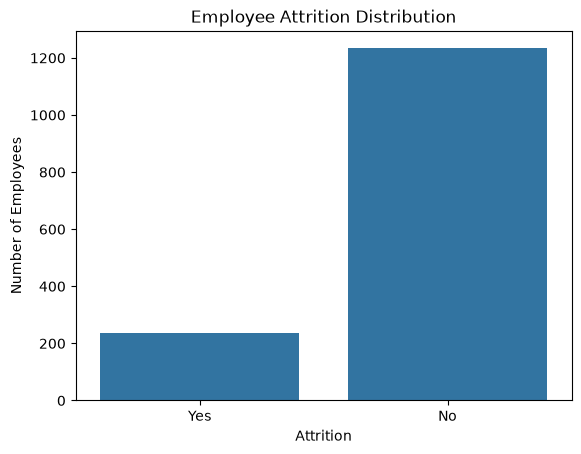

In [30]:
sns.countplot(x="Attrition", data=df)
plt.title("Employee Attrition Distribution")
plt.xlabel("Attrition")
plt.ylabel("Number of Employees")
plt.show()

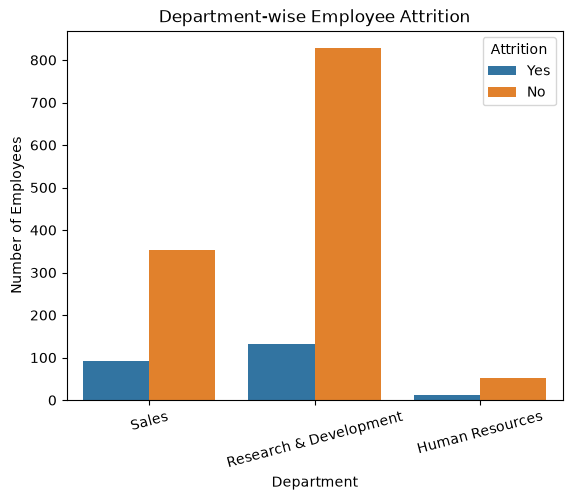

In [31]:
sns.countplot(x="Department", hue="Attrition", data=df)
plt.title("Department-wise Employee Attrition")
plt.xlabel("Department")
plt.ylabel("Number of Employees")
plt.xticks(rotation=15)
plt.show()

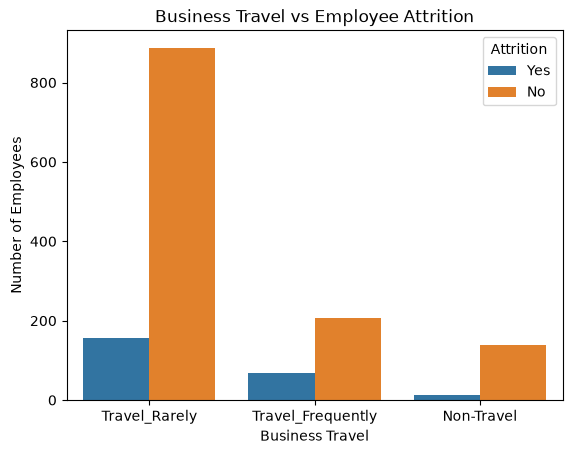

In [32]:
sns.countplot(x="BusinessTravel", hue="Attrition", data=df)
plt.title("Business Travel vs Employee Attrition")
plt.xlabel("Business Travel")
plt.ylabel("Number of Employees")
plt.show()

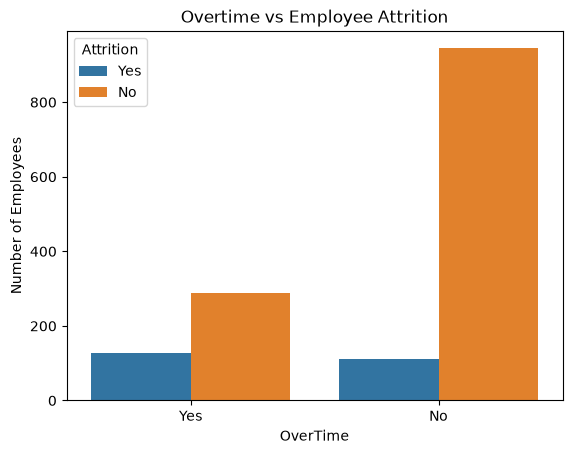

In [33]:
sns.countplot(x="OverTime", hue="Attrition", data=df)
plt.title("Overtime vs Employee Attrition")
plt.xlabel("OverTime")
plt.ylabel("Number of Employees")
plt.show()

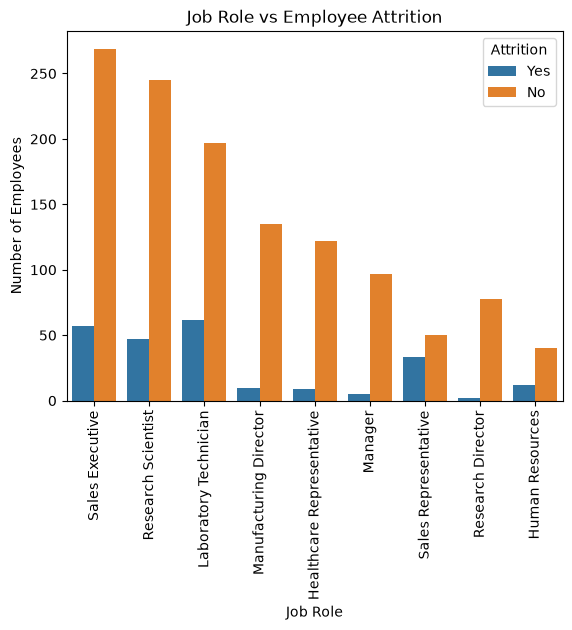

In [6]:
sns.countplot(x="JobRole", hue="Attrition", data=df)
plt.title("Job Role vs Employee Attrition")
plt.xlabel("Job Role")
plt.ylabel("Number of Employees")
plt.xticks(rotation=90)
plt.show()

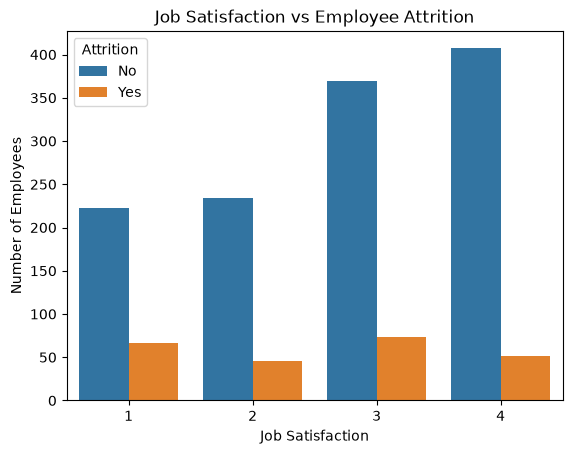

In [7]:
sns.countplot(x="JobSatisfaction", hue="Attrition", data=df)
plt.title("Job Satisfaction vs Employee Attrition")
plt.xlabel("Job Satisfaction")
plt.ylabel("Number of Employees")
plt.show()

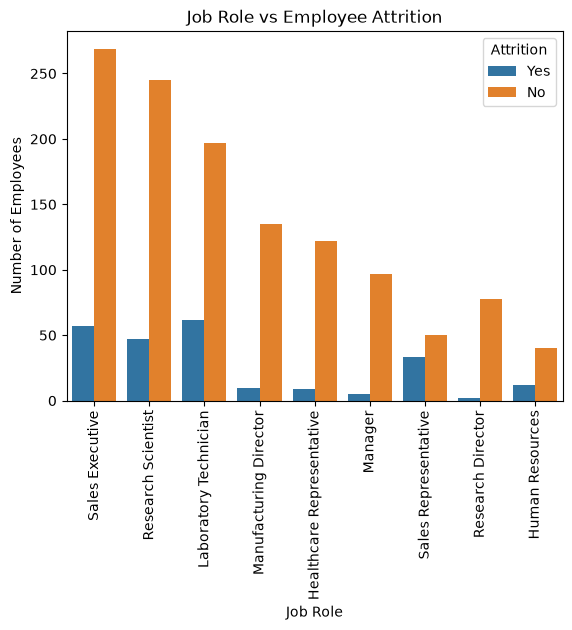

In [13]:
sns.countplot(x="JobRole", hue="Attrition", data=df)
plt.title("Job Role vs Employee Attrition")
plt.xlabel("Job Role")
plt.ylabel("Number of Employees")
plt.xticks(rotation=90)
plt.show()

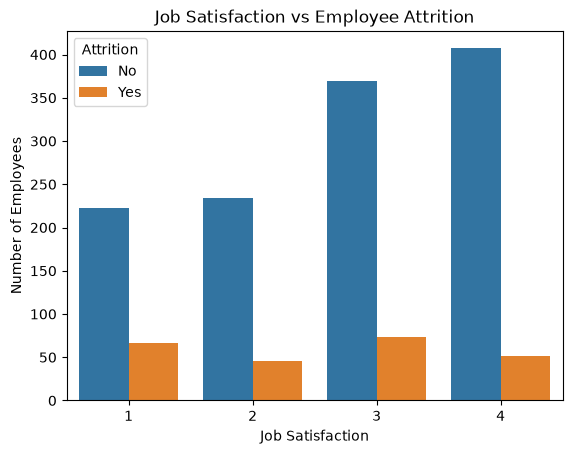

In [14]:
sns.countplot(x="JobSatisfaction", hue="Attrition", data=df)
plt.title("Job Satisfaction vs Employee Attrition")
plt.xlabel("Job Satisfaction")
plt.ylabel("Number of Employees")
plt.show()

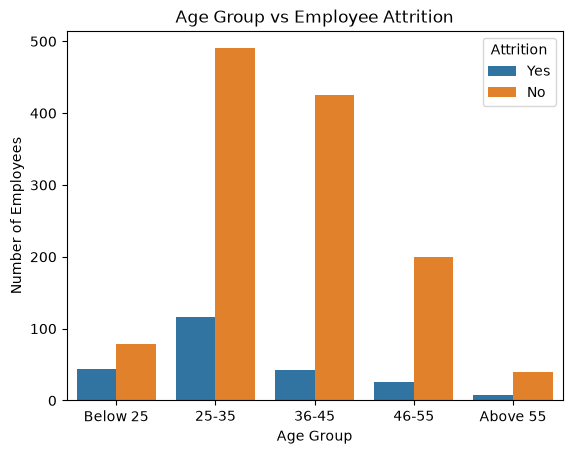

In [21]:
sns.countplot(x="AgeGroup", hue="Attrition", data=df)
plt.title("Age Group vs Employee Attrition")
plt.xlabel("Age Group")
plt.ylabel("Number of Employees")
plt.show()

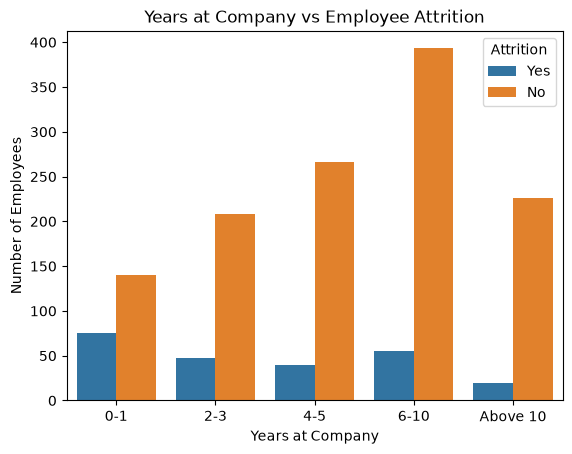

In [26]:
sns.countplot(x="YearsAtCompanyGroup", hue="Attrition", data=df)
plt.title("Years at Company vs Employee Attrition")
plt.xlabel("Years at Company")
plt.ylabel("Number of Employees")
plt.show()

## key Findings

In [27]:
df.groupby("Department")["Attrition"].apply(lambda x: (x == "Yes").mean() * 100)

Department
Human Resources           19.047619
Research & Development    13.839750
Sales                     20.627803
Name: Attrition, dtype: float64

- Sales had the highest attrition rate at 20.63%.
- Human Resources had an attrition rate of 19.05%.
- Research & Development had the lowest attrition rate at 13.84%.

In [28]:
df.groupby("BusinessTravel")["Attrition"].apply(lambda x: (x == "Yes").mean() * 100)

BusinessTravel
Non-Travel            8.000000
Travel_Frequently    24.909747
Travel_Rarely        14.956855
Name: Attrition, dtype: float64

- Employees who travelled frequently had a higher attrition rate of 24.91%.
- Employees who travelled rarely had an attrition rate of 14.96%.
- Employees who did not travel had the lowest attrition rate of 8.00%.

In [29]:
df.groupby("OverTime")["Attrition"].apply(lambda x: (x == "Yes").mean() * 100)

OverTime
No     10.436433
Yes    30.528846
Name: Attrition, dtype: float64

- Employees working overtime had a higher attrition rate of 30.53%.
- Employees not working overtime had a lower attrition rate of 10.44%.

In [30]:
df.groupby("JobSatisfaction")["Attrition"].apply(lambda x: (x == "Yes").mean() * 100)

JobSatisfaction
1    22.837370
2    16.428571
3    16.515837
4    11.328976
Name: Attrition, dtype: float64

- Employees with the lowest job satisfaction level (1) had the highest attrition rate of 22.84%.
- Employees with the highest job satisfaction level (4) had the lowest attrition rate of 11.33%.

In [31]:
df.groupby("AgeGroup")["Attrition"].apply(lambda x: (x == "Yes").mean() * 100)

AgeGroup
Below 25    35.772358
25-35       19.141914
36-45        9.188034
46-55       11.504425
Above 55    17.021277
Name: Attrition, dtype: float64

- Employees below 25 had the highest attrition rate at 35.77%.
- Employees aged 36-45 had the lowest attrition rate at 9.19%.

## Conclusion

The analysis shows that employee attrition varies across departments, business travel, overtime, job satisfaction, and age groups. Higher attrition was observed among employees who worked overtime, travelled frequently, had lower job satisfaction, and were below 25 years of age. These findings can help organizations identify employee groups that may require greater attention and develop appropriate employee retention strategies.